# 3_1_4_var_cuantitativas

Noviembre 16, 2026

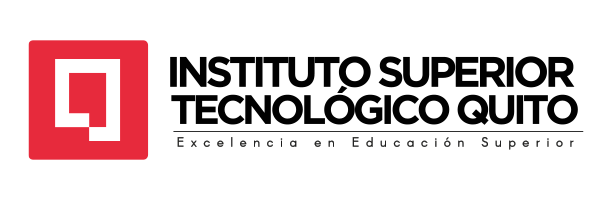

**Nombre:** Edgar Ulloa  
**Fecha:** *16-11-2026*    
**Link Repositorio:** https://github.com/eulloaitq/Fundamentos-de-Machine-Learning.git

## Variables cuantitativas

**Objetivo:** Analizar variables cuantitativas mediante la aplicación de técnicas de estadística descriptiva utilizando Python y las bibliotecas NumPy, SciPy, Matplotlib y Pandas, para calcular e interpretar medidas de tendencia central, posición, dispersión y distribución, identificar valores atípicos y representar gráficamente los resultados, aplicando estos conocimientos al conjunto de datos Iris para comprender el comportamiento de sus variables numéricas.

## Datos numéricos

La librería **numpy** se utiliza para crear un arreglo de 16 valores numéricos, tanto positivos como negativos y con decimales y el comando **print(X)** permite mostrar su contenido.

In [2]:
# Creación aleatoria de datos
import numpy as np
X = np.array([0.5, 23, 0.3, 4.5, 0.3, 0.5,
              -28, -50, 60, -100, -10, -11, 13, 19, 1, 9])
print(X)

[   0.5   23.     0.3    4.5    0.3    0.5  -28.   -50.    60.  -100.
  -10.   -11.    13.    19.     1.     9. ]


## Tendencia central

A continuación se calculan las siguientes medidas de tendencia central:

- **Media:** Representa el promedio aritmético de los datos, es sensible a los valores extremos.
- **Mediana:** Es el valor central al ordenar los datos.
- **Moda:** Es el valor más repetido dentro de los datos, aquí existen dos valores con frecuencia máxima (0.3 y 0.5), y **stats.mode** devuelve uno de ellos.

In [3]:
# Medidas de tendencia central
from scipy import stats
media = np.mean(X)
mediana = np.median(X)
moda , _ = stats.mode(X)
print('media: ', media)
print('mediana: ', mediana)
print('moda :', moda)

media:  -4.24375
mediana:  0.5
moda : 0.3


La media negativa no implica que la mayoría de los datos sean negativos sino que el valor negativo tiene mucha influencia.

## Cuartiles y rango intercuartílico

En este ejercicio **Q1** es el percentil 25 y **Q3** el percentil 75. El rango intercuartílico **IQR = Q3 - Q1** mide la dispersión que tiene la mitad central de los datos con respecto a la media. Los límites inferior **Q1 - 1.5 × IQR** y superior **Q3 + 1.5 × IQR** permiten detectar los posibles valores atípicos, estos límites no necesariamente representan los extremos de los bigotes del gráfico.

In [5]:
# Medidas de posición
import numpy as np
import matplotlib.pyplot as plt

Q1 = np.percentile(X, 25)
Q3 = np.percentile(X, 75)
IQR = Q3 - Q1
lim_inf = Q1 - 1.5 * IQR
lim_sup = Q3 + 1.5 * IQR

print('IQR: ', IQR)
print('límite inferior: ', lim_inf)
print('límite superior: ', lim_sup)

IQR:  20.25
límite inferior:  -40.625
límite superior:  40.375


## Diagrama de caja y bigotes

La función **plt.boxplot(X)** muestra graficamente la mediana, la caja entre cuartiles, los bigotes y los puntos atípicos; **plt.grid()** activa la cuadrícula, **plt.title()** coloca el título y **plt.show()** presenta el gráfico. 

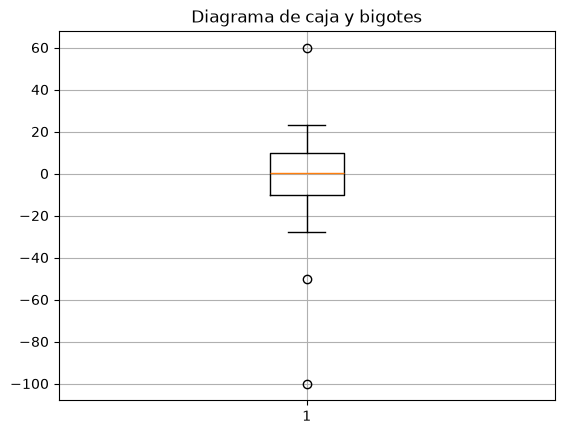

In [6]:
# Dibuja el diagrama de box and whiskers y determina visualmente el número de outliers
plt.boxplot(X)
plt.grid()
plt.title("Diagrama de caja y bigotes")
plt.show()

## Dispersión
La función **np.std(X)** calcula la desviación estándar **poblacional** con **ddof=0** que respresenta el ajuste de los grados de libertad por defecto (ddof=0 divide entre el número total de observaciones (n), mientras que ddof=1 divide entre (n−1)), su cuadrado es igual a la varianza poblacional de este modo la varianza queda expresada en unidades al cuadrado.

In [7]:
# Medidas de dispersión
desvest = np.std(X)
print('Desviación típica: ', desvest)
print('Varianza: ', desvest**2)

Desviación típica:  33.521242681880096
Varianza:  1123.6737109375


## Forma de la distribución

El comando **stats.skew** mide la asimetría si se obtiene un resultado negativo esto indica una cola más pronunciada hacia la izquierda, la función **stats.kurtosis(..., fisher=True)** calcula el exceso de curtosis aquí los valores positivos se clasifican como leptocúrticos, se utiliza los condicionales **if / elif / else** para imprimir la categoría correspondiente.

In [8]:
# Medidas de distribución
asimetria = stats.skew(X)
curtosis = stats.kurtosis(X, fisher=True) # https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kurtosis.html

print('Asimetría ', np.round(asimetria, 4))
print('Curtosis ', np.round(curtosis, 4))

if curtosis>0:
    print('Distribución Leptocúrtica')
elif curtosis<0:
    print('Distribución Platicúrtica')
else:
    print('Distribución Mesocúrtica')

Asimetría  -1.1302
Curtosis  2.2858
Distribución Leptocúrtica


## Iris: asimetría y curtosis

El comando **load_iris()** carga un conjunto de 150 flores con cuatro mediciones y tres especies. La función **X[:, 2]** extrae la longitud del pétalo y **X[:, 1]** el ancho del sépalo, aquí **skew** y **kurtosis** permiten responder las dos preguntas planteadas en esta misma celda.

In [9]:
# Cargar el set de datos de Iris
from sklearn import datasets
from pprint import pprint
from scipy.stats import skew, kurtosis
iris = datasets.load_iris()
#pprint(iris)
X = iris.data
y = iris.target

# ¿Qué tipo de asimetría se observa en la variable "longitud del pétalo"?
#???
longitud_petalo = X[:, 2]

asimetria = skew(longitud_petalo)

print("Asimetría:", asimetria)

if asimetria > 0:
    print("La variable presenta asimetría positiva (sesgo hacia la derecha).")
elif asimetria < 0:
    print("La variable presenta asimetría negativa (sesgo hacia la izquierda).")
else:
    print("La variable tiene una distribución simétrica.")

# ¿A qué tipo de distribución se ajusta la variable "ancho del sépalo", según su curtosis?
#???
ancho_sepalo = X[:, 1]

curt = kurtosis(ancho_sepalo)

print("Curtosis:", curt)

if curt > 0:
    print("La distribución es leptocúrtica.")
elif curt < 0:
    print("La distribución es platicúrtica.")
else:
    print("La distribución es mesocúrtica.")

Asimetría: -0.2721276664567214
La variable presenta asimetría negativa (sesgo hacia la izquierda).
Curtosis: 0.18097631752246768
La distribución es leptocúrtica.


## Ejercicio extra de Iris

Extraer la media y desviación típica de cada variable por clase y representarlas con **plt.errorbar**, aquí la función **np.unique(y)** obtiene las clases, **X[y == clase]** luego filtra sus observaciones, la función **np.mean(..., axis=0)** calcula cuatro medias y **np.std(..., axis=0)** sus desviaciones, finalmente, **yerr=desviacion** dibuja las barras de error. 

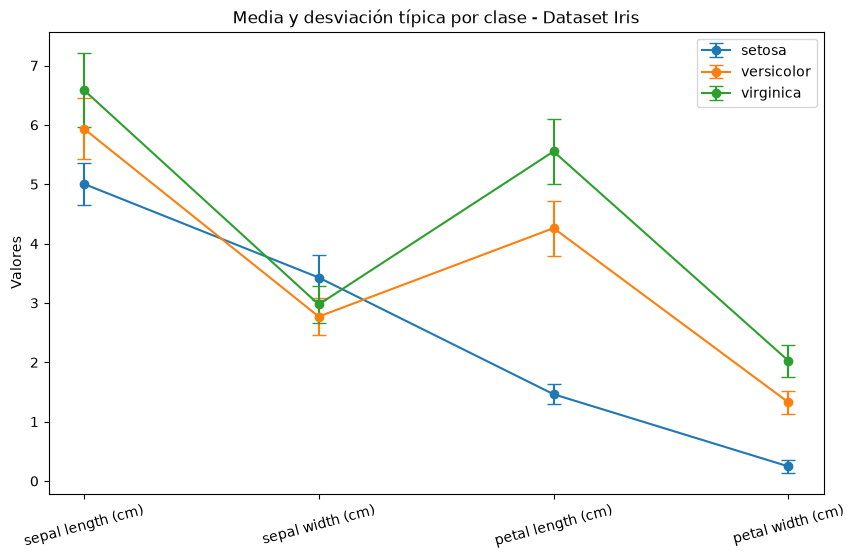

In [10]:
# EJERCICIO EXTRA SOBRE EL DATASET DE IRIS
# Extraer la media y la desviación típica de cada variable en función de la clase y representarlo en un gráfico (plt.errorbar)

# Nombres de variables
variables = iris.feature_names

# Clases
clases = np.unique(y)

# Crear figura
plt.figure(figsize=(10,6))

# Recorrer cada clase
for clase in clases:

    # Filtrar datos por clase
    datos_clase = X[y == clase]

    # Calcular media
    media = np.mean(datos_clase, axis=0)

    # Calcular desviación típica
    desviacion = np.std(datos_clase, axis=0)

    # Graficar con barras de error
    plt.errorbar(
        range(len(variables)),
        media,
        yerr=desviacion,
        marker='o',
        capsize=5,
        label=iris.target_names[clase]
    )

# Configuración del gráfico
plt.xticks(range(len(variables)), variables, rotation=15)
plt.ylabel("Valores")
plt.title("Media y desviación típica por clase - Dataset Iris")
plt.legend()

plt.show()